**Introducción a la Ciencia de Datos 2026**  
Posgrado en Ciencias de la Computación - CICESE  
Erick Gabriel Santiago Suenaga

# Tarea 4: Notebook de métricas de clasificación

Un banco portugués llamó por teléfono a sus clientes para ofrecerles un depósito a plazo, y solo 1 de cada 9 aceptó. El banco quiere un modelo que le diga a quién llamar, para no gastar llamadas en clientes que no van a aceptar.

Se usa el conjunto Bank Marketing (Moro *et al.*, 2014). Primero se hace el análisis exploratorio (EDA): estructura, calidad de los datos, variable objetivo y relaciones entre variables. Después se contestan seis preguntas: qué variable el banco no podría conocer al decidir a quién llamar, qué exactitud logra un clasificador que siempre responde «no», qué métricas da una regresión logística con el umbral de 0.5, qué muestran las curvas ROC y de precisión contra sensibilidad, a partir de qué probabilidad conviene llamar cuando se toman en cuenta los costos, y qué pasa con las métricas si se deja entrar la variable que se quitó.

---

## Preparación

Se usan NumPy, pandas y Matplotlib para los datos y las gráficas, y scikit-learn para el modelo, la partición y las métricas. Los colores son los de las sesiones anteriores: el naranja se reserva para lo que produce el modelo.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("matplotlib  ", __import__("matplotlib").__version__)
print("scikit-learn", sklearn.__version__)

numpy        2.1.3
pandas       2.2.3
matplotlib   3.10.0
scikit-learn 1.6.1


In [2]:
AZUL_OSCURO = "#112057"
AZUL = "#7697CD"
AZUL_MEDIO = "#3C51A9"
NARANJA = "#E76A28"     # lo que produce el modelo
GRIS = "#5B6584"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlecolor": AZUL_OSCURO,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelcolor": AZUL_OSCURO,
    "axes.edgecolor": "#C9CFDF",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#E3E6EF",
    "xtick.color": GRIS,
    "ytick.color": GRIS,
    "legend.frameon": False,
})
pd.set_option("display.max_columns", None)

SEMILLA = 42    # fija la partición para que los resultados se repitan

---

### Los datos

Bank Marketing. Cada fila es un cliente de un banco portugués al que se llamó por teléfono durante una campaña para ofrecerle un depósito a plazo. Las columnas describen al cliente, su último contacto, sus contactos en campañas anteriores y cinco indicadores económicos del país en ese momento.

- **Quién lo recolectó.** Sérgio Moro, Paulo Cortez y Paulo Rita, en el artículo *A data-driven approach to predict the success of bank telemarketing* (2014). Los datos vienen de campañas de telemarketing de un banco portugués, de mayo de 2008 a noviembre de 2010, y se donaron a UCI Machine Learning Repository el 13 de febrero de 2012.
- **Unidad de observación.** Un cliente contactado en una campaña, con los datos de su último contacto.
- **Archivo.** `bank-additional-full.csv` tiene los 41,188 clientes de la campaña, ordenados por fecha. Trae 20 variables de entrada y la variable objetivo `y`. El repositorio incluye también `bank-additional.csv`, una muestra aleatoria del 10 % (4,119 clientes) que no se usa aquí.
- **Variables de entrada.** Datos del cliente (`age`, `job`, `marital`, `education`, `default`, `housing`, `loan`), del último contacto (`contact`, `month`, `day_of_week`, `duration`), de campañas (`campaign`, `pdays`, `previous`, `poutcome`) y cinco indicadores socioeconómicos del Banco de Portugal (`emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed`).
- **Variable objetivo.** `y`: si el cliente contrató el depósito a plazo («yes» o «no»).
- **Faltantes.** Los faltantes de las variables categóricas vienen con la etiqueta `unknown`. En este notebook se tratan como una categoría más, una de las opciones que menciona la descripción del archivo.
- **Licencia.** Creative Commons Attribution 4.0 International (CC BY 4.0), según la página del dataset en UCI.
- **Enlace.** https://doi.org/10.24432/C5K306

El archivo separa las columnas con punto y coma, como lo publica UCI.

In [3]:
banco = pd.read_csv("bank-additional-full.csv", sep=";")

print(f"{banco.shape[0]} clientes × {banco.shape[1]} columnas")
banco.head()

41188 clientes × 21 columnas


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


---
## Análisis exploratorio (EDA)

In [4]:
NUMERICAS = banco.select_dtypes(include="number").columns.tolist()
CATEGORICAS = banco.select_dtypes(exclude="number").columns.drop("y").tolist()

resumen = pd.DataFrame({
    "tipo": np.where(banco.dtypes.map(pd.api.types.is_numeric_dtype), "numérica", "categórica"),
    "valores distintos": banco.nunique(),
    "NaN": banco.isna().sum(),
    "unknown": (banco == "unknown").sum(),
}, index=banco.columns)

print("Filas duplicadas:", banco.duplicated().sum())
print(f"pdays = 999: {(banco['pdays'] == 999).sum()} clientes ({(banco['pdays'] == 999).mean():.1%})")
print(f"duration = 0: {(banco['duration'] == 0).sum()} clientes, con y = {banco.loc[banco['duration'] == 0, 'y'].unique().tolist()}")
resumen

Filas duplicadas: 12
pdays = 999: 39673 clientes (96.3%)
duration = 0: 4 clientes, con y = ['no']


,tipo,valores distintos,NaN,unknown
age,numérica,78,0,0
job,categórica,12,0,330
marital,categórica,4,0,80
education,categórica,8,0,1731
default,categórica,3,0,8597
housing,categórica,3,0,990
loan,categórica,3,0,990
contact,categórica,2,0,0
month,categórica,10,0,0
day_of_week,categórica,5,0,0


El archivo tiene 41,188 clientes y 21 columnas: 10 numéricas y 11 categóricas, contando `y`. No hay `NaN`, y las 12 filas duplicadas (0.03 %) no se eliminan: son una fracción mínima y podrían ser clientes distintos con los mismos datos. Seis variables categóricas traen la etiqueta `unknown`: la más afectada es `default` (8,597 clientes, 20.9 %), seguida de `education` (1,731, 4.2 %), `housing` y `loan` (990 cada una, 2.4 %), `job` (330) y `marital` (80).

### Variable objetivo

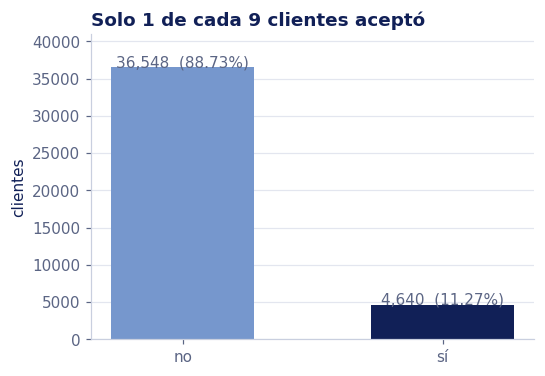

«no» por cada «sí»: 7.9


In [5]:
conteo = banco["y"].value_counts()[["no", "yes"]]

fig, ax = plt.subplots(figsize=(5.2, 3.6))
ax.bar(["no", "sí"], conteo.values, color=[AZUL, AZUL_OSCURO], width=0.55)
for i, v in enumerate(conteo.values):
    ax.text(i, v + 40, f"{v:,}  ({v / len(banco):.2%})", ha="center", color=GRIS)
ax.set_ylim(0, conteo.max() * 1.12)
ax.set_ylabel("clientes")
ax.set_title("Solo 1 de cada 9 clientes aceptó")
ax.grid(axis="x", visible=False)
plt.show()

print(f"«no» por cada «sí»: {conteo['no'] / conteo['yes']:.1f}")

Aceptaron 4,640 de los 41,188 clientes (11.27 %): unos 8 «no» por cada «sí» (36,548 contra 4,640), que es la proporción de «1 de cada 9» del enunciado. Ese desbalance hay que tenerlo presente en toda la evaluación, porque la clase que le interesa al banco es la minoritaria.

### Variables categóricas

Se comparan dos variables con diferencias relevantes en la tasa de aceptación: el resultado de campañas anteriores (`poutcome`) y el medio de contacto (`contact`). La línea punteada representa la tasa global.

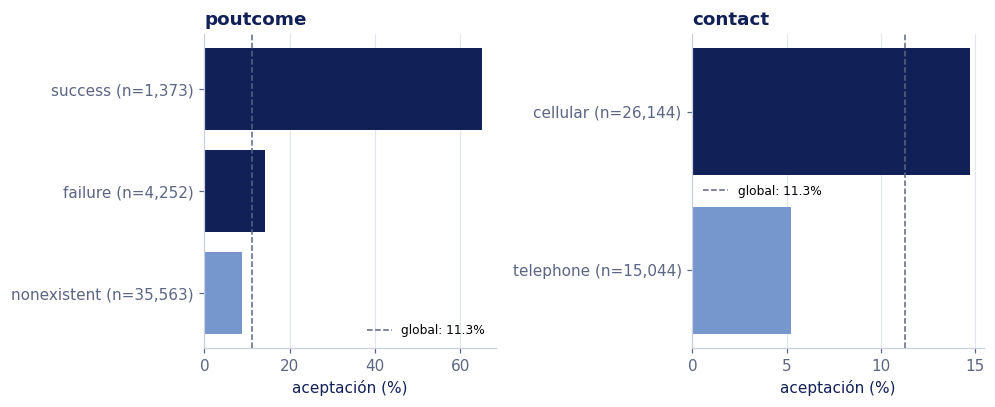

In [6]:
tasa_global = (banco["y"] == "yes").mean()
variables_relevantes = ["poutcome", "contact"]

fig, ejes = plt.subplots(1, 2, figsize=(9.2, 3.8))
for ax, col in zip(ejes, variables_relevantes):
    t = banco.groupby(col)["y"].agg(
        tasa=lambda s: (s == "yes").mean(), n="size"
    ).sort_values("tasa")
    colores = [AZUL_OSCURO if v > 1.2 * tasa_global else AZUL for v in t["tasa"]]
    ax.barh([f"{c} (n={n:,})" for c, n in zip(t.index, t["n"])],
            t["tasa"] * 100, color=colores)
    ax.axvline(tasa_global * 100, color=GRIS, linestyle="--", linewidth=1,
               label=f"global: {tasa_global:.1%}")
    ax.set_title(col)
    ax.set_xlabel("aceptación (%)")
    ax.grid(axis="y", visible=False)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

La tasa de aceptación global es 11.27 %. `poutcome` destaca: entre quienes habían aceptado en una campaña anterior, la tasa fue 65.1 %, aunque ese grupo era pequeño (1,373 clientes). El medio de contacto también se asocia con la respuesta: 14.7 % por celular frente a 5.2 % por teléfono fijo.

---

## 1. La variable que el banco no conoce

**Pregunta / Punto.** Antes de modelar, revisa `bank-additional-names.txt`. ¿Hay alguna variable que el banco no podría conocer en el momento de decidir a quién llamar? Quítala y explica por qué.

    median   mean
y                
no   163.5  220.8
sí   449.0  553.2


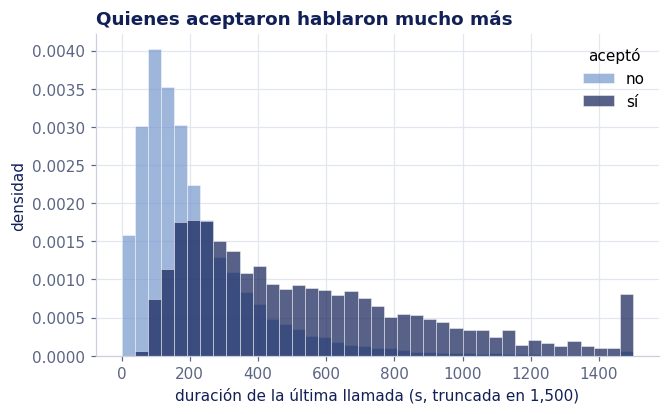

El modelo trabaja con 19 variables de entrada y 41188 clientes.


In [7]:
VARIABLE_QUITADA = "duration"

print(banco.groupby("y")[VARIABLE_QUITADA].agg(["median", "mean"]).round(1).rename(index={"no": "no", "yes": "sí"}))

fig, ax = plt.subplots(figsize=(6.6, 3.8))
bins = np.linspace(0, 1500, 40)
for clase, color, etiqueta in [("no", AZUL, "no"), ("yes", AZUL_OSCURO, "sí")]:
    ax.hist(banco.loc[banco["y"] == clase, VARIABLE_QUITADA].clip(upper=1500), bins=bins,
            density=True, color=color, alpha=0.7, edgecolor="white", linewidth=0.4, label=etiqueta)
ax.set_xlabel("duración de la última llamada (s, truncada en 1,500)")
ax.set_ylabel("densidad")
ax.set_title("Quienes aceptaron hablaron mucho más")
ax.legend(title="aceptó")
plt.show()

X = banco.drop(columns=["y", VARIABLE_QUITADA])
y = (banco["y"] == "yes").astype(int)
print(f"El modelo trabaja con {X.shape[1]} variables de entrada y {len(y)} clientes.")

**Respuesta.** La variable `duration` representa la duración en segundos de la llamada, pero esta información solo se sabe después de la llamada, ya que no se debería saber la duración de la llamada si ni siquiera se sabe si la persona contestará o no. Se quita porque dejarla haría que el modelo aprendiera de información que no existe todavía, y su desempeño parecería mucho mejor de lo que sería en una campaña real.

---

## 2. Partición estratificada y línea base

**Pregunta / Punto.** Aparta 20 % de los datos para prueba, con una partición estratificada. ¿Qué exactitud obtiene un clasificador que siempre responde no? ¿Qué dice eso de la exactitud como métrica en este problema?

`stratify=y` hace que entrenamiento y prueba conserven la proporción de clientes que aceptan, en lugar de dejarla al azar del sorteo. La línea base es `DummyClassifier` con la estrategia `most_frequent`: ignora las variables y siempre predice la clase más frecuente del entrenamiento.

In [8]:
from sklearn.model_selection import train_test_split

X_entrena, X_prueba, y_entrena, y_prueba = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEMILLA)

pd.DataFrame({
    "todos": y.value_counts(normalize=True),
    "entrenamiento": y_entrena.value_counts(normalize=True),
    "prueba": y_prueba.value_counts(normalize=True),
}).rename(index={0: "no", 1: "sí"}).round(3)

,todos,entrenamiento,prueba
y,,,
no,0.887,0.887,0.887
sí,0.113,0.113,0.113


In [9]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score

siempre_no = DummyClassifier(strategy="most_frequent").fit(X_entrena, y_entrena)
pred_siempre_no = siempre_no.predict(X_prueba)

print(f"Clientes de prueba: {len(y_prueba)} ({y_prueba.sum()} aceptan, {(y_prueba == 0).sum()} no)")
print(f"Siempre responde: {'sí' if pred_siempre_no[0] == 1 else 'no'}")
print(f"Aciertos: {(pred_siempre_no == y_prueba).sum()} de {len(y_prueba)}")
print(f"Exactitud:    {accuracy_score(y_prueba, pred_siempre_no):.3f}")
print(f"Sensibilidad: {recall_score(y_prueba, pred_siempre_no):.3f}")

Clientes de prueba: 8238 (928 aceptan, 7310 no)
Siempre responde: no
Aciertos: 7310 de 8238
Exactitud:    0.887
Sensibilidad: 0.000


**Respuesta.** Un clasificador que siempre responde «no» acierta 7,310 de los 8,238 clientes de prueba, una exactitud de 0.887, sin detectar a ninguno de los 928 que sí aceptan. La exactitud cuenta los aciertos de las dos clases juntas, y como casi todos los clientes son «no», ese número queda determinado por la clase mayoritaria y no dice nada sobre la que le interesa al banco. En este problema la exactitud sola engaña: cualquier modelo debe compararse contra ese 0.887 y evaluarse con métricas que miren a los clientes que aceptan, como la sensibilidad y la precisión.

---

## 3. Regresión logística con umbral de 0.5

**Pregunta / Punto.** Ajusta una regresión logística, con las variables categóricas en one-hot y el escalado dentro de un `Pipeline`. Con el umbral de 0.5, reporta en prueba la matriz de confusión y, a partir de ella, exactitud, precisión, sensibilidad, especificidad y F1. ¿Cuál de esas métricas le importa más al banco, y por qué?

Un `ColumnTransformer` aplica a cada tipo de columna su transformación: one-hot a las categóricas, y escalado estándar a las numéricas. Va dentro del `Pipeline`, así que el escalado y las categorías se aprenden solo con el entrenamiento. Se usa la regularización L2 que trae scikit-learn por omisión (`C=1`) y no `C=np.inf` como en `icd-12`: con 41,188 clientes la diferencia es mínima (AUC de 0.8008 contra 0.8007), pero con `C=np.inf` scikit-learn emite una advertencia porque equivale a `penalty=None`.

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def crear_modelo(X_ejemplo):
    """Pipeline: one-hot a las categóricas, escalado a las numéricas y regresión logística."""
    numericas = X_ejemplo.select_dtypes(include="number").columns.tolist()
    categoricas = X_ejemplo.select_dtypes(exclude="number").columns.tolist()
    preprocesamiento = ColumnTransformer([
        ("categoricas", OneHotEncoder(handle_unknown="ignore"), categoricas),
        ("numericas", StandardScaler(), numericas),
    ])
    return Pipeline([("preprocesamiento", preprocesamiento),
                     ("logistica", LogisticRegression(max_iter=5000))])


modelo = crear_modelo(X_entrena).fit(X_entrena, y_entrena)
proba = modelo.predict_proba(X_prueba)[:, 1]     # probabilidad de aceptar

n_columnas = modelo.named_steps["preprocesamiento"].transform(X_entrena).shape[1]
print(f"{X_entrena.shape[1]} variables de entrada → {n_columnas} columnas después del one-hot y el escalado")

19 variables de entrada → 62 columnas después del one-hot y el escalado


La probabilidad estimada para cada cliente se convierte en una decisión con el umbral de 0.5: se llama si la probabilidad es al menos 0.5. La matriz de confusión cuenta, para cada clase real (filas), cuántos clientes se predijeron en cada clase (columnas), y de sus cuatro celdas salen las métricas:

- **Exactitud:** $(TP + TN) / (TP + TN + FP + FN)$
- **Precisión:** $TP / (TP + FP)$
- **Sensibilidad:** $TP / (TP + FN)$
- **Especificidad:** $TN / (TN + FP)$
- **F1:** $2 \cdot \text{precisión} \cdot \text{sensibilidad} / (\text{precisión} + \text{sensibilidad})$

In [11]:
from sklearn.metrics import confusion_matrix


def evaluar(y_real, probabilidades, umbral=0.5):
    """Matriz de confusión y métricas a mano, para un umbral dado."""
    pred = (probabilidades >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_real, pred).ravel()
    precision = tp / (tp + fp)
    sensibilidad = tp / (tp + fn)
    return {"TN": tn, "FP": fp, "FN": fn, "TP": tp,
            "exactitud": (tp + tn) / (tp + tn + fp + fn),
            "precisión": precision,
            "sensibilidad": sensibilidad,
            "especificidad": tn / (tn + fp),
            "F1": 2 * precision * sensibilidad / (precision + sensibilidad)}


r = evaluar(y_prueba, proba, umbral=0.5)
matriz = np.array([[r["TN"], r["FP"]], [r["FN"], r["TP"]]])
pd.DataFrame(matriz, index=["real: no", "real: sí"], columns=["predicho: no", "predicho: sí"])

,predicho: no,predicho: sí
real: no,7219,91
real: sí,725,203


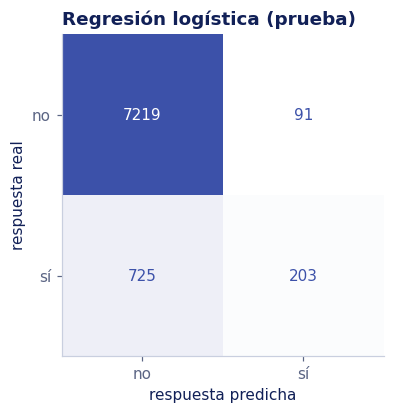

In [12]:
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import ConfusionMatrixDisplay

azules = LinearSegmentedColormap.from_list("azules", ["#FFFFFF", AZUL_MEDIO])

fig, ax = plt.subplots(figsize=(4.4, 3.8))
ConfusionMatrixDisplay(matriz, display_labels=["no", "sí"]).plot(ax=ax, cmap=azules, colorbar=False)
ax.grid(False)
ax.set_xlabel("respuesta predicha")
ax.set_ylabel("respuesta real")
ax.set_title("Regresión logística (prueba)")
plt.show()

In [13]:
from sklearn.metrics import f1_score, precision_score

metricas = pd.Series({k: r[k] for k in ["exactitud", "precisión", "sensibilidad", "especificidad", "F1"]})
pred_05 = (proba >= 0.5).astype(int)

print(metricas.round(3).to_string())
print()
print("Comprobación con scikit-learn:",
      np.allclose([accuracy_score(y_prueba, pred_05), precision_score(y_prueba, pred_05),
                   recall_score(y_prueba, pred_05), f1_score(y_prueba, pred_05)],
                  [r["exactitud"], r["precisión"], r["sensibilidad"], r["F1"]]))

exactitud        0.901
precisión        0.690
sensibilidad     0.219
especificidad    0.988
F1               0.332

Comprobación con scikit-learn: True


**Respuesta.** La métrica que más le importa al banco es la sensibilidad, porque cada cliente que habría aceptado y no recibe llamada es un ingreso de 50 perdido, mientras que una llamada de más solo cuesta 5, y con este umbral el modelo deja pasar a 725 de los 928 que habrían aceptado. La exactitud y la especificidad se ven bien solo porque casi todos los clientes son «no», y la precisión pesa menos mientras una llamada inútil cueste una fracción del ingreso que deja un cliente.

---

## 4. Curvas ROC y de precisión contra sensibilidad

**Pregunta / Punto.** Grafica la curva ROC y la curva de precisión contra sensibilidad, con su AUC y su precisión promedio. En scikit-learn, `RocCurveDisplay` y `PrecisionRecallDisplay`. ¿Qué muestra la segunda que la primera esconde cuando los positivos son pocos?

Cada punto de una curva es un umbral. La curva ROC (Fawcett, 2006) grafica la sensibilidad contra la tasa de falsos positivos, y la de precisión contra sensibilidad grafica la precisión contra la sensibilidad. En ambas se marcan tres umbrales (0.5, 0.3 y 0.1) para ver qué pasa al bajarlo. La línea punteada es lo que haría un clasificador al azar: la diagonal en la ROC, y la tasa de aceptación (0.113) en la otra.

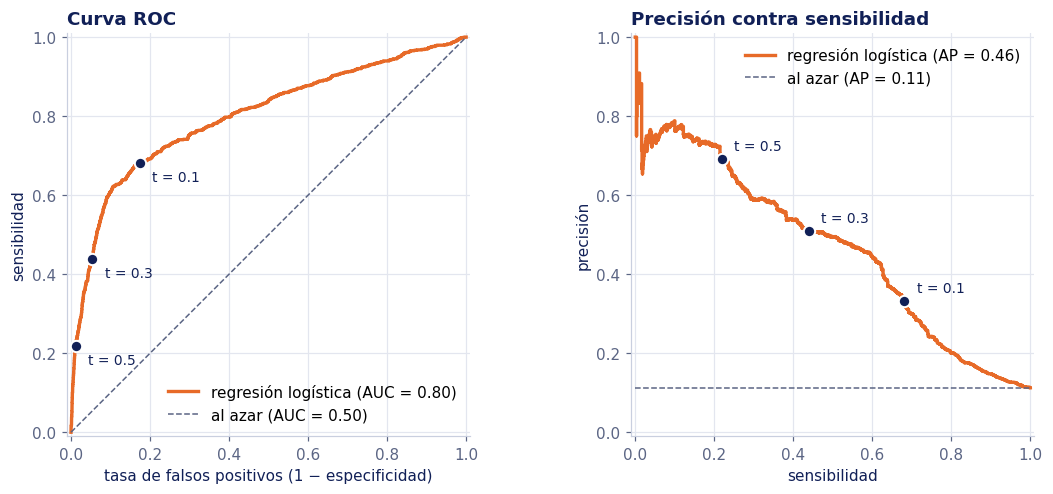

AUC (ROC):                   0.801
Precisión promedio (PR):     0.465   (al azar: 0.113)


,llamadas,sensibilidad,tasa de falsos positivos,precisión
umbral,,,,
0.5,294,0.219,0.012,0.690
0.3,801,0.439,0.054,0.508
0.1,1900,0.681,0.173,0.333


In [14]:
from sklearn.metrics import (PrecisionRecallDisplay, RocCurveDisplay,
                             average_precision_score, roc_auc_score)

auc = roc_auc_score(y_prueba, proba)
ap = average_precision_score(y_prueba, proba)
azar = {"color": GRIS, "linestyle": "--", "linewidth": 1}
azar_roc = {**azar, "label": "al azar (AUC = 0.50)"}
azar_pr = {**azar, "label": f"al azar (AP = {y_prueba.mean():.2f})"}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.4, 4.6))
RocCurveDisplay.from_predictions(y_prueba, proba, name="regresión logística", ax=ax1,
                                 plot_chance_level=True, chance_level_kw=azar_roc)
PrecisionRecallDisplay.from_predictions(y_prueba, proba, name="regresión logística", ax=ax2,
                                        plot_chance_level=True, chance_level_kw=azar_pr)
for ax in (ax1, ax2):
    ax.lines[0].set_color(NARANJA)      # la primera línea es la curva del modelo
    ax.lines[0].set_linewidth(2.2)

puntos = []
for t in [0.5, 0.3, 0.1]:
    e = evaluar(y_prueba, proba, umbral=t)
    fpr = e["FP"] / (e["FP"] + e["TN"])
    puntos.append({"umbral": t, "llamadas": e["TP"] + e["FP"], "sensibilidad": e["sensibilidad"],
                   "tasa de falsos positivos": fpr, "precisión": e["precisión"]})
    ax1.scatter(fpr, e["sensibilidad"], s=55, color=AZUL_OSCURO, edgecolor="white", linewidth=1.3, zorder=3)
    ax1.annotate(f"t = {t}", (fpr, e["sensibilidad"]), xytext=(8, -12), textcoords="offset points",
                 color=AZUL_OSCURO, fontsize=9)
    ax2.scatter(e["sensibilidad"], e["precisión"], s=55, color=AZUL_OSCURO, edgecolor="white", linewidth=1.3, zorder=3)
    ax2.annotate(f"t = {t}", (e["sensibilidad"], e["precisión"]), xytext=(8, 6), textcoords="offset points",
                 color=AZUL_OSCURO, fontsize=9)

ax1.set_xlabel("tasa de falsos positivos (1 − especificidad)")
ax1.set_ylabel("sensibilidad")
ax1.set_title("Curva ROC")
ax1.legend(loc="lower right")
ax2.set_xlabel("sensibilidad")
ax2.set_ylabel("precisión")
ax2.set_title("Precisión contra sensibilidad")
ax2.legend(loc="upper right")
plt.tight_layout()
plt.show()

print(f"AUC (ROC):                   {auc:.3f}")
print(f"Precisión promedio (PR):     {ap:.3f}   (al azar: {y_prueba.mean():.3f})")
pd.DataFrame(puntos).set_index("umbral").round(3)

**Respuesta.** Cuando los positivos son pocos, la ROC luce favorable porque sus falsos positivos se dividen entre los 7,310 clientes «no»: con el umbral de 0.1 la tasa de falsos positivos es de solo 0.173, aunque eso equivale a 1,268 llamadas inútiles para encontrar 632 aceptantes. La curva de precisión contra sensibilidad muestra ese costo porque divide entre las llamadas que se hacen: al bajar el umbral de 0.5 a 0.1 la sensibilidad sube de 0.219 a 0.681, pero la precisión cae de 0.690 a 0.333 (Saito y Rehmsmeier, 2015).

---

## 5. El umbral que conviene al banco

**Pregunta / Punto.** Cada llamada cuesta 5, acepte o no el cliente, y cada cliente que acepta deja un ingreso de 50. ¿A partir de qué probabilidad conviene llamar? Compara en prueba la ganancia total con el umbral de 0.5 y con el tuyo.

Si la probabilidad de que un cliente acepte es $p$, llamarlo deja en promedio $50p - 5$. Conviene llamar cuando eso es al menos cero, es decir, cuando $p \geq 5/50 = 0.10$ (Elkan, 2001). Esta regla supone que las probabilidades del modelo están razonablemente calibradas. La ganancia total en prueba es $50 \cdot (\text{aceptan}) - 5 \cdot (\text{llamadas})$.

In [15]:
COSTO_LLAMADA = 5
INGRESO = 50
umbral_costo = COSTO_LLAMADA / INGRESO       # 0.10: la ganancia esperada de llamar es cero


def ganancia(y_real, probabilidades, umbral):
    """Llamadas, aceptantes y ganancia total al llamar a quien tenga probabilidad >= umbral."""
    llama = np.asarray(probabilidades) >= umbral
    aceptan = int(np.asarray(y_real)[llama].sum())
    return {"llamadas": int(llama.sum()), "aceptan": aceptan,
            "ganancia": INGRESO * aceptan - COSTO_LLAMADA * int(llama.sum())}


comparacion = pd.DataFrame({
    "no llamar a nadie": ganancia(y_prueba, proba, 1.01),
    "llamar a todos": ganancia(y_prueba, proba, 0.0),
    "umbral 0.5": ganancia(y_prueba, proba, 0.5),
    f"umbral {umbral_costo:.2f}": ganancia(y_prueba, proba, umbral_costo),
}).T

print(f"Umbral por costos: {COSTO_LLAMADA} / {INGRESO} = {umbral_costo:.2f}")
comparacion

Umbral por costos: 5 / 50 = 0.10


,llamadas,aceptan,ganancia
no llamar a nadie,0,0,0
llamar a todos,8238,928,5210
umbral 0.5,294,203,8680
umbral 0.10,1900,632,22100


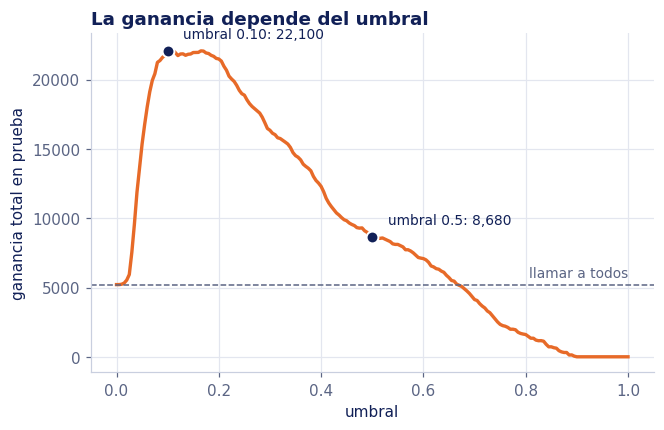

Máximo de la curva en prueba: 22,225 con umbral 0.105


In [16]:
umbrales = np.linspace(0, 1, 201)
ganancias = [ganancia(y_prueba, proba, t)["ganancia"] for t in umbrales]

fig, ax = plt.subplots(figsize=(6.6, 4))
ax.plot(umbrales, ganancias, color=NARANJA, linewidth=2.2)
ax.axhline(comparacion.loc["llamar a todos", "ganancia"], color=GRIS, linestyle="--", linewidth=1)
ax.text(1.0, comparacion.loc["llamar a todos", "ganancia"] + 0.025 * max(ganancias), "llamar a todos",
        color=GRIS, ha="right", fontsize=9)
for t, etiqueta in [(0.5, "0.5"), (umbral_costo, f"{umbral_costo:.2f}")]:
    g = ganancia(y_prueba, proba, t)["ganancia"]
    ax.scatter(t, g, s=60, color=AZUL_OSCURO, edgecolor="white", linewidth=1.3, zorder=3)
    ax.annotate(f"umbral {etiqueta}: {g:,}", (t, g), xytext=(10, 8), textcoords="offset points",
                color=AZUL_OSCURO, fontsize=9)
ax.set_xlabel("umbral")
ax.set_ylabel("ganancia total en prueba")
ax.set_title("La ganancia depende del umbral")
plt.show()

mejor = int(np.argmax(ganancias))
print(f"Máximo de la curva en prueba: {ganancias[mejor]:,} con umbral {umbrales[mejor]:.3f}")

**Respuesta.** Conviene llamar cuando la ganancia esperada es positiva, es decir, cuando 50p − 5 ≥ 0, y eso ocurre a partir de una probabilidad de 5/50 = 0.10. En los 8,238 clientes de prueba, el umbral de 0.5 llama a 294 clientes, 203 aceptan y la ganancia total es de 8,680, mientras que el umbral de 0.10 llama a 1,900, 632 aceptan y la ganancia sube a 22,100. Bajar el umbral multiplica la ganancia por 2.5 porque con 0.5 el modelo es tan prudente que deja sin llamar a 725 clientes que habrían aceptado, y aun así ambos superan a llamar a todos, que deja 5,210, y a no llamar a nadie, que deja 0.

---

## 6. La variable que se quitó

**Pregunta / Punto.** La variable que quitaste. Repite el punto 3 incluyéndola. ¿Qué les pasa a las métricas? ¿Le servirían al banco?

Se repite el mismo procedimiento del punto 3, con la misma partición (los mismos clientes en entrenamiento y en prueba) y el mismo `Pipeline`, pero con `duration` entre las variables de entrada.

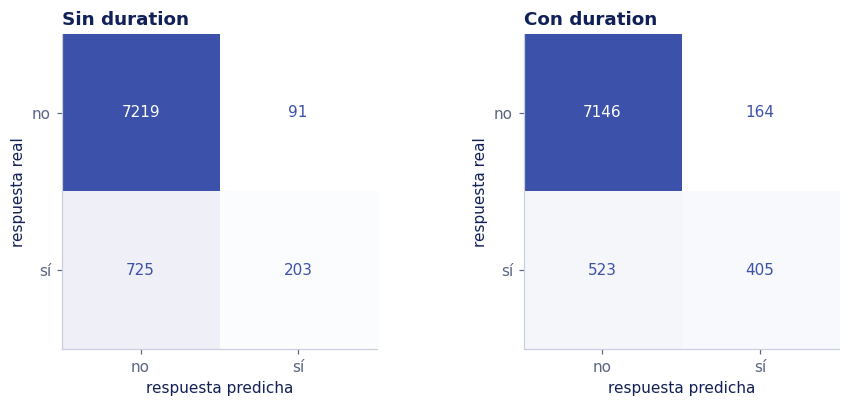

,sin duration,con duration,cambio
exactitud,0.901,0.917,0.016
precisión,0.690,0.712,0.021
sensibilidad,0.219,0.436,0.218
especificidad,0.988,0.978,-0.010
F1,0.332,0.541,0.209
AUC,0.801,0.942,0.142


In [17]:
X_entrena_con = banco.loc[X_entrena.index].drop(columns="y")
X_prueba_con = banco.loc[X_prueba.index].drop(columns="y")

modelo_con = crear_modelo(X_entrena_con).fit(X_entrena_con, y_entrena)
proba_con = modelo_con.predict_proba(X_prueba_con)[:, 1]

r_con = evaluar(y_prueba, proba_con, umbral=0.5)
matriz_con = np.array([[r_con["TN"], r_con["FP"]], [r_con["FN"], r_con["TP"]]])

fig, ejes = plt.subplots(1, 2, figsize=(8.6, 3.8))
for ax, m, titulo in [(ejes[0], matriz, "Sin duration"), (ejes[1], matriz_con, "Con duration")]:
    ConfusionMatrixDisplay(m, display_labels=["no", "sí"]).plot(ax=ax, cmap=azules, colorbar=False)
    ax.grid(False)
    ax.set_xlabel("respuesta predicha")
    ax.set_ylabel("respuesta real")
    ax.set_title(titulo)
plt.tight_layout()
plt.show()

nombres = ["exactitud", "precisión", "sensibilidad", "especificidad", "F1"]
comparacion_modelos = pd.DataFrame({
    "sin duration": [r[k] for k in nombres] + [roc_auc_score(y_prueba, proba)],
    "con duration": [r_con[k] for k in nombres] + [roc_auc_score(y_prueba, proba_con)],
}, index=nombres + ["AUC"])
comparacion_modelos["cambio"] = comparacion_modelos["con duration"] - comparacion_modelos["sin duration"]
comparacion_modelos.round(3)

**Respuesta.** Al incluir `duration`, la sensibilidad sube de 0.219 a 0.436, el F1 de 0.332 a 0.541, la precisión de 0.690 a 0.712 y la exactitud de 0.901 a 0.917, y el AUC pasa de 0.801 a 0.942. No le servirían al banco, porque `duration` solo se conoce cuando la llamada ya terminó: el modelo estaría usando como entrada una consecuencia del interés del cliente y no algo que se pueda saber antes de decidir. Esas métricas no se pueden alcanzar en una campaña real, y el modelo quedaría inservible justo cuando se necesita, que es antes de marcar.

---

## Conclusión

El banco necesita decidir a quién llamar antes de marcar, y eso obliga a quitar `duration`, que solo se conoce después de la llamada. Con las demás variables, una regresión logística con el umbral de 0.5 acierta el 90.1 % de los clientes de prueba, apenas por encima del 88.7 % de responder siempre «no», y detecta solo 203 de los 928 que aceptan: la exactitud esconde que casi no encuentra a la clase que interesa. La curva de precisión contra sensibilidad muestra por qué es difícil, ya que al llamar a más clientes la precisión cae pronto, y el AUC de 0.801 solo dice que el modelo ordena a los clientes mejor que el azar. Lo que cambia el resultado es el umbral: con los costos del banco conviene llamar desde una probabilidad de 0.10, y con ese umbral la ganancia en prueba pasa de 8,680 a 22,100, mucho más que llamar a todos (5,210). Incluir `duration` mejoraría mucho las métricas (AUC de 0.942), pero esas cifras no se pueden obtener cuando hay que decidir.

---

## Declaración de uso de IA generativa

Este notebook utilizó Claude (Anthropic) como asistente para estructurar el notebook (Markdown), redactar y revisar los textos, así como la depuración de código.

## Referencias

- Moro, S., Cortez, P., & Rita, P. (2014). A data-driven approach to predict the success of bank telemarketing. *Decision Support Systems*, 62, 22-31. https://doi.org/10.1016/j.dss.2014.03.001
- Moro, S., Rita, P., & Cortez, P. *Bank Marketing* [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C5K306. Licencia CC BY 4.0.
- Kaufman, S., Rosset, S., Perlich, C., & Stitelman, O. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM Transactions on Knowledge Discovery from Data*, 6(4), 1-21.
- Fawcett, T. (2006). An introduction to ROC analysis. *Pattern Recognition Letters*, 27(8), 861-874.
- Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLOS ONE*, 10(3), e0118432.
- Elkan, C. (2001). The foundations of cost-sensitive learning. *Proceedings of the 17th International Joint Conference on Artificial Intelligence (IJCAI)*, 973-978.
- [scikit-learn: métricas de clasificación](https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics) · [RocCurveDisplay](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.RocCurveDisplay.html) · [PrecisionRecallDisplay](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.PrecisionRecallDisplay.html) · [ColumnTransformer](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html)